## Imports

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import cv2

from sklearn.preprocessing import minmax_scale

import torch
import torch.optim as optim
from torch.utils.data import DataLoader

from torchvision.datasets import VisionDataset
from torchvision.transforms import v2
from torchvision import tv_tensors

import segmentation_models_pytorch as smp

from torchmetrics import Dice
from tqdm import tqdm

## Utils & Functions

In [2]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [3]:
class AverageMeter(object):
    """Computes and stores the average and current value"""
    def __init__(self):
        self.reset()

    def reset(self):
        self.val = 0
        self.avg = 0
        self.sum = 0
        self.count = 0

    def update(self, val, n=1):
        self.val = val
        self.sum += val * n
        self.count += n
        self.avg = self.sum / self.count

In [ ]:
def train_one_epoch(model, train_loader, loss_fn, optimizer, epoch=None):
    model.train()
    loss_train = AverageMeter()
    dice_train = Dice().to(device)
    with tqdm(train_loader, unit="batch") as tepoch:
        for inputs, targets in tepoch:
            if epoch is not None:
                tepoch.set_description(f"Epoch {epoch}")
            inputs = inputs.to(device)
            targets = targets.to(device)

            optimizer.zero_grad()

            outputs = model(inputs)
      
            loss = loss_fn(outputs, targets)

            loss.backward()
            optimizer.step()

            loss_train.update(loss.item())
            dice_train(outputs, targets.int())
            tepoch.set_postfix(loss=loss_train.avg, dice=dice_train.compute().item())
    return model, loss_train.avg, dice_train.compute().item()

In [5]:
def validation(model, test_loader, loss_fn):
    model.eval()
    with torch.no_grad():
        loss_valid = AverageMeter()
        dice_valid = Dice().to(device)
        for i, (inputs, targets) in enumerate(test_loader):
            inputs = inputs.to(device)
            targets = targets.to(device)

            outputs = model(inputs)
            loss = loss_fn(outputs, targets)
      
            loss_valid.update(loss.item())
            dice_valid(outputs, targets.int())
    return loss_valid.avg, dice_valid.compute().item()

In [6]:
def rle2mask(rle, shape):
    rle_list = rle.split(' ')
    rle_list = np.array(rle_list, dtype=np.uint32)
    starts = rle_list[::2] - 1
    lengths = rle_list[1::2]
    mask = np.zeros(shape[0] * shape[1])
    for s,l in zip(starts,lengths):
        mask[s:s+l] = 1
    return mask.reshape(shape)


def masks(df, row, sample):
    masks = np.zeros((3, sample.shape[0], sample.shape[1]))
    if pd.notna(df.iloc[row]['stomach']):
        masks[0, :, :] = rle2mask(df.iloc[row]['stomach'], sample.shape)
    
    if pd.notna(df.iloc[row]['large_bowel']):
        masks[1, :, :] = rle2mask(df.iloc[row]['large_bowel'], sample.shape)
    
    if pd.notna(df.iloc[row]['small_bowel']):
        masks[2, :, :] = rle2mask(df.iloc[row]['small_bowel'], sample.shape)
    
    return masks

In [7]:
def set_seed(seed):
  np.random.seed(seed)
  torch.manual_seed(seed)
  if torch.cuda.is_available():
      torch.cuda.manual_seed(seed)

## Dataset & Transforms

In [ ]:
train_df = pd.read_csv('./splits_data/train_df.csv')
valid_df = pd.read_csv('./splits_data/valid_df.csv')
test_df = pd.read_csv('./splits_data/test_df.csv')

In [16]:
class ImageDataset(VisionDataset):
    def __init__(self, dataframe, transforms=None, memory=False):
        super().__init__(transforms=transforms)
        self.df = dataframe
        self.classes = ['Stomach', 'Large Bowel', 'Small Bowel']
        self.memory = memory
        if memory:
            self.save_memory()

    def __getitem__(self, row):
        img = self.imgs[row] if self.memory else cv2.imread(self.df.iloc[row]['path'], cv2.IMREAD_UNCHANGED).astype(np.float32)
        img = img.squeeze()
        #img = cv2.imread(self.df.iloc[row]['path'], cv2.IMREAD_UNCHANGED).astype(np.float32)
        mask = masks(self.df, row, img)
        img = tv_tensors.Image(img)
        mask = tv_tensors.Mask(mask)
        img, mask = self.transforms(img, mask)
        return img, mask
        
    def __len__(self):
        return self.df.shape[0]

    def save_memory(self):
        self.imgs = []
        for path in self.df['path']:
            img = cv2.imread(path, cv2.IMREAD_UNCHANGED).astype(np.float32)
            img = tv_tensors.Image(minmax_scale(img))
            self.imgs.append(img)

In [17]:
train_transform = v2.Compose([
    v2.Resize(size=(234, 234)),
    v2.RandomCrop(size=(224, 224)),
    v2.RandomHorizontalFlip(p=0.5),
    v2.RandomVerticalFlip(p=0.5),
    v2.Lambda(lambda x: (x - x.min()) / (x.max() - x.min())),
    v2.Normalize(mean=(0.5,), std=(0.5,))
    ])

test_transform = v2.Compose([
    v2.Resize(size=(224, 224)),
    v2.Lambda(lambda x: (x - x.min()) / (x.max() - x.min())),
    v2.Normalize(mean=(0.5,), std=(0.5,))
    ])

In [14]:
train_set = ImageDataset(train_df, transforms=train_transform, memory=True)
valid_set = ImageDataset(valid_df, transforms=test_transform, memory=True)
test_set = ImageDataset(test_df, transforms=test_transform, memory=False)

torch.Size([1, 224, 224]) torch.Size([3, 224, 224]) [-1.0, 1.0] tensor([0., 1.], dtype=torch.float64)


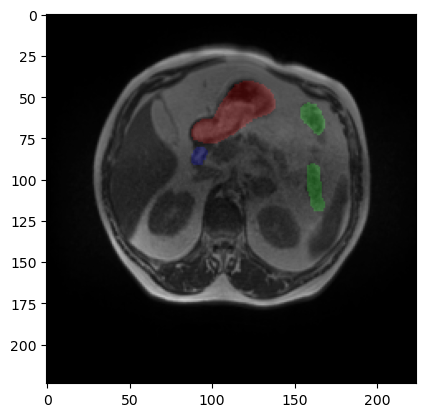

In [164]:
item = np.random.randint(0, len(train_set))
img, mask = train_set[item]
print(img.shape, mask.shape, [img.min().item(), img.max().item()], mask.unique())
plt.imshow(img[0], cmap='gray')
plt.imshow(mask.permute(1,2,0), alpha=0.2)

In [15]:
train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
valid_loader = DataLoader(valid_set, batch_size=32, shuffle=True)
test_loader = DataLoader(test_set, batch_size=32, shuffle=False)

In [117]:
print(train_loader.dataset.df.shape)
print(valid_loader.dataset.df.shape)
print(test_loader.dataset.df.shape)

(12030, 10)
(1493, 10)
(3067, 10)


## Unet

### Initial Loss

In [152]:
model = smp.Unet(encoder_name='resnet34', in_channels=1, classes=3).to(device)
loss_fn = smp.losses.DiceLoss('multilabel')

inputs, targets = next(iter(train_loader))
inputs = inputs.to(device)
targets = targets.to(device)

with torch.no_grad():
  outputs = model(inputs)
  loss = loss_fn(outputs, targets)

print(loss)

tensor(0.9738, device='cuda:0')


### Best Learning Rate (Adam optimizer)

In [179]:
loss_fn = smp.losses.DiceLoss('multilabel')

num_epochs = 3

for lr in [0.5, 0.3, 0.1, 0.01, 0.001]:
  print(f'LR={lr}')

  model = smp.Unet(encoder_name='resnet34', in_channels=1, classes=3).to(device)
  optimizer = torch.optim.Adam(model.parameters(), lr=lr)

  for epoch in range(num_epochs):
    model, _, _ = train_one_epoch(model, valid_loader, loss_fn, optimizer, epoch+1)

  print()

LR=0.5


Epoch 3: 100%|██████████| 47/47 [00:16<00:00,  2.86batch/s, dice=0.395, loss=0.703]



LR=0.3


Epoch 3: 100%|██████████| 47/47 [00:16<00:00,  2.85batch/s, dice=0.363, loss=0.64] 



LR=0.1


Epoch 3: 100%|██████████| 47/47 [00:16<00:00,  2.78batch/s, dice=0.395, loss=0.598]



LR=0.01


Epoch 3: 100%|██████████| 47/47 [00:16<00:00,  2.83batch/s, dice=0.575, loss=0.408]



LR=0.001


Epoch 3: 100%|██████████| 47/47 [00:16<00:00,  2.84batch/s, dice=0.807, loss=0.207]

In [182]:
num_epochs = 3

for lr in [0.0009, 0.001, 0.002, 0.003, 0.005]:
  print(f'LR={lr}')

  model = smp.Unet(encoder_name='resnet34', in_channels=1, classes=3).to(device)
  optimizer = torch.optim.Adam(model.parameters(), lr=lr)

  for epoch in range(num_epochs):
    model, _, _ = train_one_epoch(model, valid_loader, loss_fn, optimizer, epoch+1)

  print()

LR=0.0009


Epoch 3: 100%|██████████| 47/47 [00:17<00:00,  2.71batch/s, dice=0.804, loss=0.216]



LR=0.001


Epoch 3: 100%|██████████| 47/47 [00:21<00:00,  2.22batch/s, dice=0.813, loss=0.21] 



LR=0.002


Epoch 3: 100%|██████████| 47/47 [00:16<00:00,  2.77batch/s, dice=0.776, loss=0.222]



LR=0.003


Epoch 3: 100%|██████████| 47/47 [00:17<00:00,  2.63batch/s, dice=0.751, loss=0.245]



LR=0.005


Epoch 3: 100%|██████████| 47/47 [00:17<00:00,  2.72batch/s, dice=0.717, loss=0.281]

### Best Learning Rate (SGD Optimizer)

In [181]:
num_epochs = 3

for lr in [0.9, 0.5, 0.3, 0.1, 0.01, 0.001]:
  print(f'LR={lr}')

  model = smp.Unet(encoder_name='resnet34', in_channels=1, classes=3).to(device)
  optimizer = optim.SGD(model.parameters(), lr=lr, weight_decay=1e-4, momentum=0.9)

  for epoch in range(num_epochs):
    model, _, _ = train_one_epoch(model, valid_loader, loss_fn, optimizer, epoch+1)

  print()

LR=0.9


Epoch 3: 100%|██████████| 47/47 [00:16<00:00,  2.86batch/s, dice=0.623, loss=0.337]



LR=0.5


Epoch 3: 100%|██████████| 47/47 [00:16<00:00,  2.83batch/s, dice=0.699, loss=0.292]



LR=0.3


Epoch 3: 100%|██████████| 47/47 [00:16<00:00,  2.80batch/s, dice=0.74, loss=0.256] 


... (2 outputs left out)


LR=0.01


Epoch 3: 100%|██████████| 47/47 [00:17<00:00,  2.74batch/s, dice=0.147, loss=0.941]



LR=0.001


Epoch 3: 100%|██████████| 47/47 [00:17<00:00,  2.72batch/s, dice=0.0302, loss=0.969]

In [184]:
num_epochs = 3

for lr in [0.3, 0.25, 0.2, 0.15, 0.1]:
  print(f'LR={lr}')

  model = smp.Unet(encoder_name='resnet34', in_channels=1, classes=3).to(device)
  optimizer = optim.SGD(model.parameters(), lr=lr, weight_decay=1e-4, momentum=0.9)

  for epoch in range(num_epochs):
    model, _, _ = train_one_epoch(model, valid_loader, loss_fn, optimizer, epoch+1)

  print()

LR=0.3


Epoch 3: 100%|██████████| 47/47 [00:16<00:00,  2.77batch/s, dice=0.59, loss=0.373] 



LR=0.25


Epoch 3: 100%|██████████| 47/47 [00:17<00:00,  2.72batch/s, dice=0.639, loss=0.314]



LR=0.2


Epoch 3: 100%|██████████| 47/47 [00:16<00:00,  2.85batch/s, dice=0.679, loss=0.311]



LR=0.15


Epoch 3: 100%|██████████| 47/47 [00:16<00:00,  2.81batch/s, dice=0.724, loss=0.273]



LR=0.1


Epoch 3: 100%|██████████| 47/47 [00:16<00:00,  2.77batch/s, dice=0.644, loss=0.347]

### Train

In [12]:
set_seed(0)
model = smp.Unet(encoder_name='resnet34', in_channels=1, classes=3).to(device)

In [13]:
loss_train_hist = []
loss_valid_hist = []

dice_train_hist = []
dice_valid_hist = []

best_loss_valid = torch.inf
epoch_counter = 0

In [14]:
set_seed(0)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loss_fn = smp.losses.DiceLoss('multilabel')

In [ ]:
num_epochs = 10

for epoch in range(num_epochs):
  model, loss_train, dice_train = train_one_epoch(model, train_loader, loss_fn, optimizer, epoch_counter + 1)

  loss_valid, dice_valid = validation(model, valid_loader, loss_fn)
  
  loss_train_hist.append(loss_train)
  loss_valid_hist.append(loss_valid)

  dice_train_hist.append(dice_train)
  dice_valid_hist.append(dice_valid)
  
  if loss_valid < best_loss_valid:
    torch.save(model, f'./models/Unet(Resnet34).pt')
    best_loss_valid = loss_valid
    print('Model Saved.')

  print(f'Valid: Loss = {loss_valid:.4}, Dice = {dice_valid:.4}')
  print()

  epoch_counter += 1

Epoch 1: 100%|██████████| 376/376 [02:36<00:00,  2.41batch/s, dice=0.574, loss=0.404]


Model Saved.
Valid: Loss = 0.3146, Dice = 0.6888



Epoch 2: 100%|██████████| 376/376 [02:33<00:00,  2.46batch/s, dice=0.739, loss=0.259]


Model Saved.
Valid: Loss = 0.2712, Dice = 0.73



Epoch 3: 100%|██████████| 376/376 [02:33<00:00,  2.45batch/s, dice=0.765, loss=0.231]


Model Saved.
Valid: Loss = 0.2681, Dice = 0.7176



... (10 outputs left out)

Epoch 9: 100%|██████████| 376/376 [02:46<00:00,  2.26batch/s, dice=0.823, loss=0.171]


Valid: Loss = 0.2378, Dice = 0.7499



Epoch 10: 100%|██████████| 376/376 [02:57<00:00,  2.12batch/s, dice=0.826, loss=0.168]


Valid: Loss = 0.2197, Dice = 0.7728



In [ ]:
num_epochs = 2

for epoch in range(num_epochs):
  model, loss_train, dice_train = train_one_epoch(model, train_loader, loss_fn, optimizer, epoch_counter + 1)

  loss_valid, dice_valid = validation(model, valid_loader, loss_fn)
  
  loss_train_hist.append(loss_train)
  loss_valid_hist.append(loss_valid)

  dice_train_hist.append(dice_train)
  dice_valid_hist.append(dice_valid)
  
  if loss_valid < best_loss_valid:
    torch.save(model, f'./models/Unet(Resnet34).pt')
    best_loss_valid = loss_valid
    print('Model Saved.')

  print(f'Valid: Loss = {loss_valid:.4}, Dice = {dice_valid:.4}')
  print()

  epoch_counter += 1

Epoch 11: 100%|██████████| 376/376 [02:28<00:00,  2.53batch/s, dice=0.832, loss=0.162]


Valid: Loss = 0.2272, Dice = 0.7651



Epoch 12: 100%|██████████| 376/376 [02:28<00:00,  2.52batch/s, dice=0.833, loss=0.161]


Valid: Loss = 0.2253, Dice = 0.7627



In [ ]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)
num_epochs = 2

for epoch in range(num_epochs):
  model, loss_train, dice_train = train_one_epoch(model, train_loader, loss_fn, optimizer, epoch_counter + 1)

  loss_valid, dice_valid = validation(model, valid_loader, loss_fn)
  
  loss_train_hist.append(loss_train)
  loss_valid_hist.append(loss_valid)

  dice_train_hist.append(dice_train)
  dice_valid_hist.append(dice_valid)
  
  if loss_valid < best_loss_valid:
    torch.save(model, f'./models/Unet(Resnet34).pt')
    best_loss_valid = loss_valid
    print('Model Saved.')

  print(f'Valid: Loss = {loss_valid:.4}, Dice = {dice_valid:.4}')
  print()

  epoch_counter += 1

Epoch 13: 100%|██████████| 376/376 [02:28<00:00,  2.53batch/s, dice=0.853, loss=0.141]


Model Saved.
Valid: Loss = 0.1915, Dice = 0.8034



Epoch 14: 100%|██████████| 376/376 [02:29<00:00,  2.52batch/s, dice=0.858, loss=0.137]


Model Saved.
Valid: Loss = 0.19, Dice = 0.8049



In [ ]:
num_epochs = 2

for epoch in range(num_epochs):
  model, loss_train, dice_train = train_one_epoch(model, train_loader, loss_fn, optimizer, epoch_counter + 1)

  loss_valid, dice_valid = validation(model, valid_loader, loss_fn)
  
  loss_train_hist.append(loss_train)
  loss_valid_hist.append(loss_valid)

  dice_train_hist.append(dice_train)
  dice_valid_hist.append(dice_valid)
  
  if loss_valid < best_loss_valid:
    torch.save(model, f'./models/Unet(Resnet34).pt')
    best_loss_valid = loss_valid
    print('Model Saved.')

  print(f'Valid: Loss = {loss_valid:.4}, Dice = {dice_valid:.4}')
  print()

  epoch_counter += 1

Epoch 15: 100%|██████████| 376/376 [02:27<00:00,  2.55batch/s, dice=0.861, loss=0.134]


Valid: Loss = 0.1913, Dice = 0.8038



Epoch 16: 100%|██████████| 376/376 [02:28<00:00,  2.53batch/s, dice=0.862, loss=0.132]


Valid: Loss = 0.1936, Dice = 0.7992



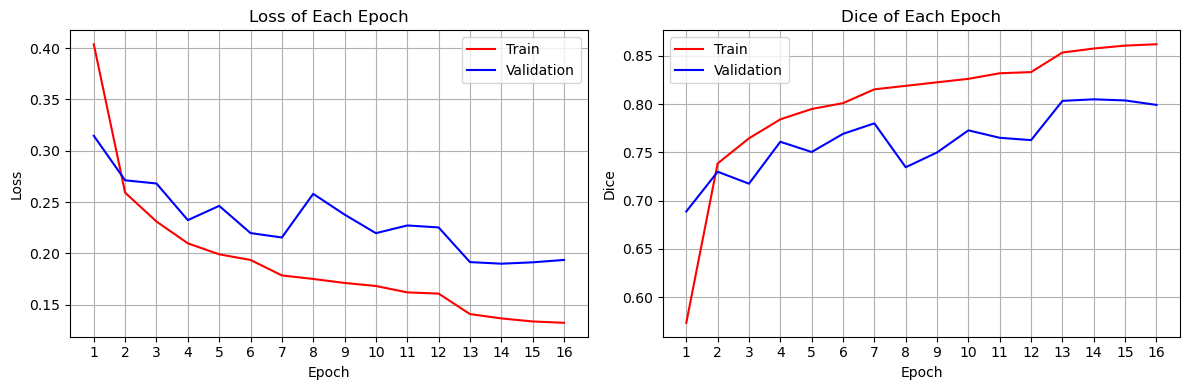

In [88]:
epochs = list(range(1, epoch_counter + 1))

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.lineplot(x=epochs, y=loss_train_hist, label='Train', color='r')
sns.lineplot(x=epochs, y=loss_valid_hist, label='Validation', color='b')
plt.title('Loss of Each Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)
plt.xticks(epochs) 

plt.subplot(1, 2, 2)
sns.lineplot(x=epochs, y=dice_train_hist, label='Train', color='r')
sns.lineplot(x=epochs, y=dice_valid_hist, label='Validation', color='b')
plt.title('Dice of Each Epoch')
plt.xlabel('Epoch')
plt.ylabel('Dice')
plt.grid(True)
plt.xticks(epochs) 

plt.tight_layout()
plt.show()

In [ ]:
unet_data = {
    'loss_train_hist': loss_train_hist,
    'loss_valid_hist': loss_valid_hist,
    'dice_train_hist': dice_train_hist,
    'dice_valid_hist': dice_valid_hist
}

df = pd.DataFrame(unet_data)

df.to_csv('./models_data/unet_data.csv', index=True)
df

,loss_train_hist,loss_valid_hist,dice_train_hist,dice_valid_hist
0,0.403761,0.314630,0.573584,0.688819
1,0.259155,0.271211,0.738548,0.729986
2,0.231085,0.268117,0.764556,0.717616
3,0.209799,0.232413,0.784224,0.761001
4,0.199111,0.246305,0.794950,0.750408
5,0.193617,0.219808,0.800982,0.769210
6,0.178549,0.215495,0.815298,0.780056
7,0.175106,0.258023,0.818888,0.734639
8,0.171217,0.237824,0.822582,0.749946
9,0.168250,0.219712,0.826146,0.772822


## Unet++

### Initial Loss

In [32]:
model = smp.UnetPlusPlus(encoder_name='resnet34', in_channels=1, classes=3).to(device)
loss_fn = smp.losses.DiceLoss('multilabel')

inputs, targets = next(iter(train_loader))
inputs = inputs.to(device)
targets = targets.to(device)

with torch.no_grad():
  outputs = model(inputs)
  loss = loss_fn(outputs, targets)

print(loss)

tensor(0.9720, device='cuda:0')


### Best Learning Rate (Adam Optimizer)

In [34]:
loss_fn = smp.losses.DiceLoss('multilabel')

num_epochs = 3

for lr in [0.5, 0.3, 0.1, 0.01, 0.001]:
  print(f'LR={lr}')

  model = smp.UnetPlusPlus(encoder_name='resnet34', in_channels=1, classes=3).to(device)
  optimizer = torch.optim.Adam(model.parameters(), lr=lr)

  for epoch in range(num_epochs):
    model, _, _ = train_one_epoch(model, valid_loader, loss_fn, optimizer, epoch+1)

  print()

LR=0.5


Epoch 3: 100%|██████████| 47/47 [00:30<00:00,  1.56batch/s, dice=0.331, loss=0.683]



LR=0.3


Epoch 3: 100%|██████████| 47/47 [00:30<00:00,  1.56batch/s, dice=0.371, loss=0.648]



LR=0.1


Epoch 3: 100%|██████████| 47/47 [00:30<00:00,  1.55batch/s, dice=0.432, loss=0.56] 



LR=0.01


Epoch 3: 100%|██████████| 47/47 [00:30<00:00,  1.53batch/s, dice=0.677, loss=0.323]



LR=0.001


Epoch 3: 100%|██████████| 47/47 [00:30<00:00,  1.55batch/s, dice=0.842, loss=0.169]

In [36]:
num_epochs = 3

for lr in [0.0009, 0.001, 0.002, 0.003, 0.005]:
  print(f'LR={lr}')

  model = smp.UnetPlusPlus(encoder_name='resnet34', in_channels=1, classes=3).to(device)
  optimizer = torch.optim.Adam(model.parameters(), lr=lr)

  for epoch in range(num_epochs):
    model, _, _ = train_one_epoch(model, valid_loader, loss_fn, optimizer, epoch+1)

  print()

LR=0.0009


Epoch 3: 100%|██████████| 47/47 [00:30<00:00,  1.55batch/s, dice=0.835, loss=0.188]



LR=0.001


Epoch 3: 100%|██████████| 47/47 [00:30<00:00,  1.52batch/s, dice=0.85, loss=0.163] 



LR=0.002


Epoch 3: 100%|██████████| 47/47 [00:31<00:00,  1.47batch/s, dice=0.836, loss=0.167]



LR=0.003


Epoch 3: 100%|██████████| 47/47 [00:30<00:00,  1.53batch/s, dice=0.792, loss=0.204]



LR=0.005


Epoch 3: 100%|██████████| 47/47 [00:30<00:00,  1.52batch/s, dice=0.767, loss=0.232]

### Train

In [20]:
set_seed(0)
model = smp.UnetPlusPlus(encoder_name='resnet34', in_channels=1, classes=3).to(device)

In [42]:
loss_train_hist = []
loss_valid_hist = []

dice_train_hist = []
dice_valid_hist = []

best_loss_valid = torch.inf
epoch_counter = 0

In [21]:
set_seed(0)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loss_fn = smp.losses.DiceLoss('multilabel')

In [ ]:
num_epochs = 5

for epoch in range(num_epochs):
  model, loss_train, dice_train = train_one_epoch(model, train_loader, loss_fn, optimizer, epoch_counter + 1)

  loss_valid, dice_valid = validation(model, valid_loader, loss_fn)
  
  loss_train_hist.append(loss_train)
  loss_valid_hist.append(loss_valid)

  dice_train_hist.append(dice_train)
  dice_valid_hist.append(dice_valid)
  
  if loss_valid < best_loss_valid:
    torch.save(model, f'./models/UnetPlusPlus(Resnet34).pt')
    best_loss_valid = loss_valid
    print('Model Saved.')

  print(f'Valid: Loss = {loss_valid:.4}, Dice = {dice_valid:.4}')
  print()

  epoch_counter += 1

Epoch 1: 100%|██████████| 376/376 [04:22<00:00,  1.43batch/s, dice=0.536, loss=0.405]


Model Saved.
Valid: Loss = 0.2849, Dice = 0.7069



Epoch 2: 100%|██████████| 376/376 [04:19<00:00,  1.45batch/s, dice=0.748, loss=0.249]


Model Saved.
Valid: Loss = 0.2599, Dice = 0.7363



Epoch 3: 100%|██████████| 376/376 [04:18<00:00,  1.45batch/s, dice=0.78, loss=0.215] 


Model Saved.
Valid: Loss = 0.2587, Dice = 0.7371



Epoch 4: 100%|██████████| 376/376 [04:19<00:00,  1.45batch/s, dice=0.783, loss=0.214]


Model Saved.
Valid: Loss = 0.2276, Dice = 0.769



Epoch 5: 100%|██████████| 376/376 [04:17<00:00,  1.46batch/s, dice=0.802, loss=0.193]


Model Saved.
Valid: Loss = 0.2124, Dice = 0.7803



In [ ]:
num_epochs = 3

for epoch in range(num_epochs):
  model, loss_train, dice_train = train_one_epoch(model, train_loader, loss_fn, optimizer, epoch_counter + 1)

  loss_valid, dice_valid = validation(model, valid_loader, loss_fn)
  
  loss_train_hist.append(loss_train)
  loss_valid_hist.append(loss_valid)

  dice_train_hist.append(dice_train)
  dice_valid_hist.append(dice_valid)
  
  if loss_valid < best_loss_valid:
    torch.save(model, f'./models/UnetPlusPlus(Resnet34).pt')
    best_loss_valid = loss_valid
    print('Model Saved.')

  print(f'Valid: Loss = {loss_valid:.4}, Dice = {dice_valid:.4}')
  print()

  epoch_counter += 1

Epoch 6: 100%|██████████| 376/376 [04:12<00:00,  1.49batch/s, dice=0.812, loss=0.182]


Valid: Loss = 0.2143, Dice = 0.7812



Epoch 7: 100%|██████████| 376/376 [04:13<00:00,  1.48batch/s, dice=0.817, loss=0.176]


Valid: Loss = 0.2135, Dice = 0.7806



Epoch 8: 100%|██████████| 376/376 [04:14<00:00,  1.48batch/s, dice=0.826, loss=0.168]


Model Saved.
Valid: Loss = 0.2017, Dice = 0.7923



In [ ]:
num_epochs = 2

for epoch in range(num_epochs):
  model, loss_train, dice_train = train_one_epoch(model, train_loader, loss_fn, optimizer, epoch_counter + 1)

  loss_valid, dice_valid = validation(model, valid_loader, loss_fn)
  
  loss_train_hist.append(loss_train)
  loss_valid_hist.append(loss_valid)

  dice_train_hist.append(dice_train)
  dice_valid_hist.append(dice_valid)
  
  if loss_valid < best_loss_valid:
    torch.save(model, f'./models/UnetPlusPlus(Resnet34).pt')
    best_loss_valid = loss_valid
    print('Model Saved.')

  print(f'Valid: Loss = {loss_valid:.4}, Dice = {dice_valid:.4}')
  print()

  epoch_counter += 1

Epoch 9: 100%|██████████| 376/376 [04:18<00:00,  1.45batch/s, dice=0.827, loss=0.167]


Valid: Loss = 0.2041, Dice = 0.7887



Epoch 10: 100%|██████████| 376/376 [04:18<00:00,  1.45batch/s, dice=0.835, loss=0.159]


Valid: Loss = 0.21, Dice = 0.7808



In [ ]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)
num_epochs = 2

for epoch in range(num_epochs):
  model, loss_train, dice_train = train_one_epoch(model, train_loader, loss_fn, optimizer, epoch_counter + 1)

  loss_valid, dice_valid = validation(model, valid_loader, loss_fn)
  
  loss_train_hist.append(loss_train)
  loss_valid_hist.append(loss_valid)

  dice_train_hist.append(dice_train)
  dice_valid_hist.append(dice_valid)
  
  if loss_valid < best_loss_valid:
    torch.save(model, f'./models/UnetPlusPlus(Resnet34).pt')
    best_loss_valid = loss_valid
    print('Model Saved.')

  print(f'Valid: Loss = {loss_valid:.4}, Dice = {dice_valid:.4}')
  print()

  epoch_counter += 1

Epoch 11: 100%|██████████| 376/376 [04:19<00:00,  1.45batch/s, dice=0.854, loss=0.14] 


Model Saved.
Valid: Loss = 0.1789, Dice = 0.8137



Epoch 12: 100%|██████████| 376/376 [04:13<00:00,  1.48batch/s, dice=0.86, loss=0.135] 


Model Saved.
Valid: Loss = 0.1774, Dice = 0.8169



In [ ]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)
num_epochs = 2

for epoch in range(num_epochs):
  model, loss_train, dice_train = train_one_epoch(model, train_loader, loss_fn, optimizer, epoch_counter + 1)

  loss_valid, dice_valid = validation(model, valid_loader, loss_fn)
  
  loss_train_hist.append(loss_train)
  loss_valid_hist.append(loss_valid)

  dice_train_hist.append(dice_train)
  dice_valid_hist.append(dice_valid)
  
  if loss_valid < best_loss_valid:
    torch.save(model, f'./models/UnetPlusPlus(Resnet34).pt')
    best_loss_valid = loss_valid
    print('Model Saved.')

  print(f'Valid: Loss = {loss_valid:.4}, Dice = {dice_valid:.4}')
  print()

  epoch_counter += 1

Epoch 13: 100%|██████████| 376/376 [04:00<00:00,  1.57batch/s, dice=0.863, loss=0.132]


Model Saved.
Valid: Loss = 0.1773, Dice = 0.816



Epoch 14: 100%|██████████| 376/376 [03:59<00:00,  1.57batch/s, dice=0.865, loss=0.129]


Model Saved.
Valid: Loss = 0.1753, Dice = 0.819



In [ ]:
num_epochs = 2

for epoch in range(num_epochs):
  model, loss_train, dice_train = train_one_epoch(model, train_loader, loss_fn, optimizer, epoch_counter + 1)

  loss_valid, dice_valid = validation(model, valid_loader, loss_fn)
  
  loss_train_hist.append(loss_train)
  loss_valid_hist.append(loss_valid)

  dice_train_hist.append(dice_train)
  dice_valid_hist.append(dice_valid)
  
  if loss_valid < best_loss_valid:
    torch.save(model, f'./models/UnetPlusPlus(Resnet34).pt')
    best_loss_valid = loss_valid
    print('Model Saved.')

  print(f'Valid: Loss = {loss_valid:.4}, Dice = {dice_valid:.4}')
  print()

  epoch_counter += 1

Epoch 15: 100%|██████████| 376/376 [04:03<00:00,  1.54batch/s, dice=0.867, loss=0.127]


Valid: Loss = 0.1771, Dice = 0.817



Epoch 16: 100%|██████████| 376/376 [04:13<00:00,  1.48batch/s, dice=0.869, loss=0.126]


Valid: Loss = 0.178, Dice = 0.8167



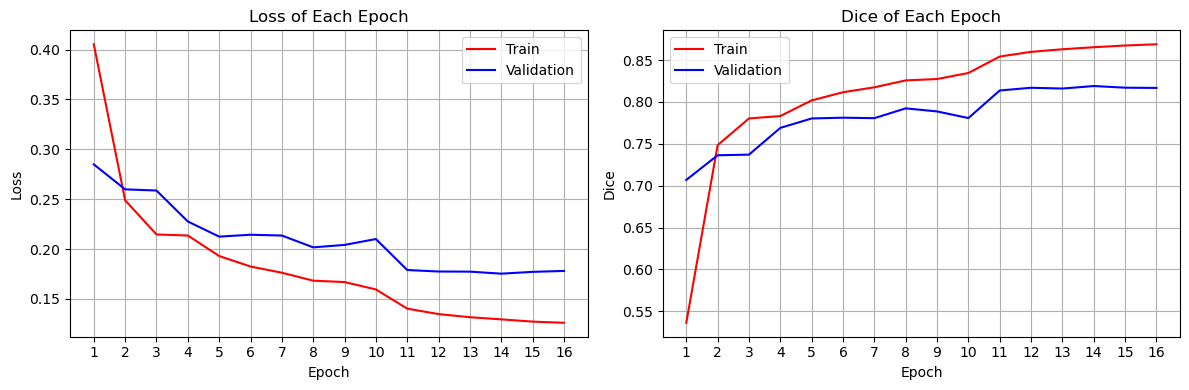

In [95]:
epochs = list(range(1, epoch_counter + 1))

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.lineplot(x=epochs, y=loss_train_hist, label='Train', color='r')
sns.lineplot(x=epochs, y=loss_valid_hist, label='Validation', color='b')
plt.title('Loss of Each Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)
plt.xticks(epochs) 

plt.subplot(1, 2, 2)
sns.lineplot(x=epochs, y=dice_train_hist, label='Train', color='r')
sns.lineplot(x=epochs, y=dice_valid_hist, label='Validation', color='b')
plt.title('Dice of Each Epoch')
plt.xlabel('Epoch')
plt.ylabel('Dice')
plt.grid(True)
plt.xticks(epochs) 

plt.tight_layout()
plt.show()

In [ ]:
unetplusplus_data = {
    'loss_train_hist': loss_train_hist,
    'loss_valid_hist': loss_valid_hist,
    'dice_train_hist': dice_train_hist,
    'dice_valid_hist': dice_valid_hist
}

df = pd.DataFrame(unetplusplus_data)

df.to_csv('./models_data/unetplusplus_data.csv', index=True)
df

,loss_train_hist,loss_valid_hist,dice_train_hist,dice_valid_hist
0,0.405412,0.284927,0.536313,0.706920
1,0.248848,0.259863,0.748390,0.736328
2,0.214618,0.258668,0.780299,0.737086
3,0.213530,0.227619,0.783149,0.769014
4,0.192963,0.212433,0.801842,0.780281
5,0.182449,0.214319,0.811582,0.781189
6,0.176202,0.213528,0.817485,0.780626
7,0.168238,0.201663,0.825729,0.792320
8,0.166834,0.204120,0.827342,0.788675
9,0.159454,0.209997,0.834553,0.780757


## Deeplab V3+

### Initial Loss

In [31]:
model = smp.DeepLabV3Plus(encoder_name='resnet34', in_channels=1, classes=3).to(device)
loss_fn = smp.losses.DiceLoss('multilabel')

inputs, targets = next(iter(train_loader))
inputs = inputs.to(device)
targets = targets.to(device)

with torch.no_grad():
  outputs = model(inputs)
  loss = loss_fn(outputs, targets)

print(loss)

tensor(0.9626, device='cuda:0')


### Best Learning Rate (Adam Optimizer)

In [33]:
loss_fn = smp.losses.DiceLoss('multilabel')

num_epochs = 3

for lr in [0.5, 0.3, 0.1, 0.01, 0.001]:
  print(f'LR={lr}')

  model = smp.DeepLabV3Plus(encoder_name='resnet34', in_channels=1, classes=3).to(device)
  optimizer = torch.optim.Adam(model.parameters(), lr=lr)

  for epoch in range(num_epochs):
    model, _, _ = train_one_epoch(model, valid_loader, loss_fn, optimizer, epoch+1)

  print()

LR=0.5


Epoch 3: 100%|██████████| 47/47 [00:15<00:00,  3.11batch/s, dice=0.407, loss=0.59] 



LR=0.3


Epoch 3: 100%|██████████| 47/47 [00:14<00:00,  3.29batch/s, dice=0.464, loss=0.65] 



LR=0.1


Epoch 3: 100%|██████████| 47/47 [00:13<00:00,  3.37batch/s, dice=0.565, loss=0.433]



LR=0.01


Epoch 3: 100%|██████████| 47/47 [00:13<00:00,  3.36batch/s, dice=0.673, loss=0.329]



LR=0.001


Epoch 3: 100%|██████████| 47/47 [00:14<00:00,  3.26batch/s, dice=0.811, loss=0.206]

In [34]:
num_epochs = 3

for lr in [0.0009, 0.001, 0.002, 0.003, 0.005]:
  print(f'LR={lr}')

  model = smp.DeepLabV3Plus(encoder_name='resnet34', in_channels=1, classes=3).to(device)
  optimizer = torch.optim.Adam(model.parameters(), lr=lr)

  for epoch in range(num_epochs):
    model, _, _ = train_one_epoch(model, valid_loader, loss_fn, optimizer, epoch+1)

  print()

LR=0.0009


Epoch 3: 100%|██████████| 47/47 [00:14<00:00,  3.29batch/s, dice=0.814, loss=0.203]



LR=0.001


Epoch 3: 100%|██████████| 47/47 [00:13<00:00,  3.39batch/s, dice=0.815, loss=0.199]



LR=0.002


Epoch 3: 100%|██████████| 47/47 [00:13<00:00,  3.40batch/s, dice=0.792, loss=0.214]



LR=0.003


Epoch 3: 100%|██████████| 47/47 [00:13<00:00,  3.42batch/s, dice=0.779, loss=0.224]



LR=0.005


Epoch 3: 100%|██████████| 47/47 [00:15<00:00,  3.02batch/s, dice=0.737, loss=0.264]

### Train

In [39]:
set_seed(0)
model = smp.DeepLabV3Plus(encoder_name='resnet34', in_channels=1, classes=3).to(device)

In [40]:
loss_train_hist = []
loss_valid_hist = []

dice_train_hist = []
dice_valid_hist = []

best_loss_valid = torch.inf
epoch_counter = 0

In [41]:
set_seed(0)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loss_fn = smp.losses.DiceLoss('multilabel')

In [ ]:
num_epochs = 10

for epoch in range(num_epochs):
  model, loss_train, dice_train = train_one_epoch(model, train_loader, loss_fn, optimizer, epoch_counter + 1)

  loss_valid, dice_valid = validation(model, valid_loader, loss_fn)
  
  loss_train_hist.append(loss_train)
  loss_valid_hist.append(loss_valid)

  dice_train_hist.append(dice_train)
  dice_valid_hist.append(dice_valid)
  
  if loss_valid < best_loss_valid:
    torch.save(model, f'./models/DeepLabv3P(Resnet34).pt')
    best_loss_valid = loss_valid
    print('Model Saved.')

  print(f'Valid: Loss = {loss_valid:.4}, Dice = {dice_valid:.4}')
  print()

  epoch_counter += 1

Epoch 1: 100%|██████████| 376/376 [01:59<00:00,  3.15batch/s, dice=0.46, loss=0.437] 


Model Saved.
Valid: Loss = 0.329, Dice = 0.6624



Epoch 2: 100%|██████████| 376/376 [02:00<00:00,  3.13batch/s, dice=0.733, loss=0.269]


Model Saved.
Valid: Loss = 0.2626, Dice = 0.7396



Epoch 3: 100%|██████████| 376/376 [02:00<00:00,  3.13batch/s, dice=0.769, loss=0.228]


Valid: Loss = 0.2737, Dice = 0.7266



... (10 outputs left out)

Epoch 9: 100%|██████████| 376/376 [02:01<00:00,  3.08batch/s, dice=0.833, loss=0.162]


Model Saved.
Valid: Loss = 0.2228, Dice = 0.7725



Epoch 10: 100%|██████████| 376/376 [02:01<00:00,  3.10batch/s, dice=0.841, loss=0.154]


Model Saved.
Valid: Loss = 0.2204, Dice = 0.7723



In [ ]:
num_epochs = 2

for epoch in range(num_epochs):
  model, loss_train, dice_train = train_one_epoch(model, train_loader, loss_fn, optimizer, epoch_counter + 1)

  loss_valid, dice_valid = validation(model, valid_loader, loss_fn)
  
  loss_train_hist.append(loss_train)
  loss_valid_hist.append(loss_valid)

  dice_train_hist.append(dice_train)
  dice_valid_hist.append(dice_valid)
  
  if loss_valid < best_loss_valid:
    torch.save(model, f'./models/DeepLabv3P(Resnet34).pt')
    best_loss_valid = loss_valid
    print('Model Saved.')

  print(f'Valid: Loss = {loss_valid:.4}, Dice = {dice_valid:.4}')
  print()

  epoch_counter += 1

Epoch 11: 100%|██████████| 376/376 [02:01<00:00,  3.10batch/s, dice=0.842, loss=0.154]


Valid: Loss = 0.225, Dice = 0.7679



Epoch 12: 100%|██████████| 376/376 [02:01<00:00,  3.09batch/s, dice=0.849, loss=0.147]


Valid: Loss = 0.2236, Dice = 0.7725



In [ ]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)
num_epochs = 4

for epoch in range(num_epochs):
  model, loss_train, dice_train = train_one_epoch(model, train_loader, loss_fn, optimizer, epoch_counter + 1)

  loss_valid, dice_valid = validation(model, valid_loader, loss_fn)
  
  loss_train_hist.append(loss_train)
  loss_valid_hist.append(loss_valid)

  dice_train_hist.append(dice_train)
  dice_valid_hist.append(dice_valid)
  
  if loss_valid < best_loss_valid:
    torch.save(model, f'./models/DeepLabv3P(Resnet34).pt')
    best_loss_valid = loss_valid
    print('Model Saved.')

  print(f'Valid: Loss = {loss_valid:.4}, Dice = {dice_valid:.4}')
  print()

  epoch_counter += 1

Epoch 13: 100%|██████████| 376/376 [02:00<00:00,  3.13batch/s, dice=0.863, loss=0.134]


Model Saved.
Valid: Loss = 0.2086, Dice = 0.7879



Epoch 14: 100%|██████████| 376/376 [02:01<00:00,  3.10batch/s, dice=0.867, loss=0.129]


Model Saved.
Valid: Loss = 0.2031, Dice = 0.7921



Epoch 15: 100%|██████████| 376/376 [01:58<00:00,  3.19batch/s, dice=0.869, loss=0.127]


Valid: Loss = 0.2033, Dice = 0.7906



Epoch 16: 100%|██████████| 376/376 [02:00<00:00,  3.12batch/s, dice=0.871, loss=0.125]


Model Saved.
Valid: Loss = 0.2017, Dice = 0.7918



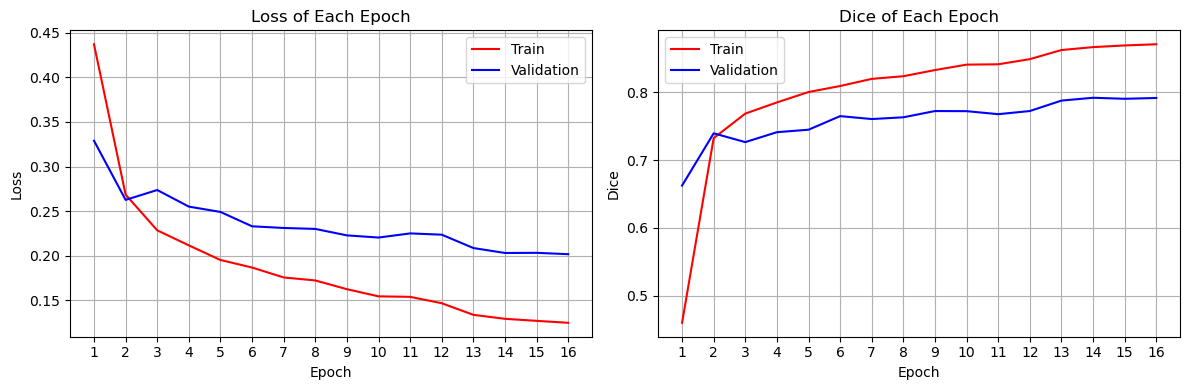

In [100]:
epochs = list(range(1, epoch_counter + 1))

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.lineplot(x=epochs, y=loss_train_hist, label='Train', color='r')
sns.lineplot(x=epochs, y=loss_valid_hist, label='Validation', color='b')
plt.title('Loss of Each Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)
plt.xticks(epochs) 

plt.subplot(1, 2, 2)
sns.lineplot(x=epochs, y=dice_train_hist, label='Train', color='r')
sns.lineplot(x=epochs, y=dice_valid_hist, label='Validation', color='b')
plt.title('Dice of Each Epoch')
plt.xlabel('Epoch')
plt.ylabel('Dice')
plt.grid(True)
plt.xticks(epochs) 

plt.tight_layout()
plt.show()


In [ ]:
deeplabv3p_data = {
    'loss_train_hist': loss_train_hist,
    'loss_valid_hist': loss_valid_hist,
    'dice_train_hist': dice_train_hist,
    'dice_valid_hist': dice_valid_hist
}

df = pd.DataFrame(deeplabv3p_data)

df.to_csv('./models_data/deeplabv3p_data.csv', index=True)
df

,loss_train_hist,loss_valid_hist,dice_train_hist,dice_valid_hist
0,0.437134,0.328998,0.459747,0.662397
1,0.268540,0.262622,0.732560,0.739619
2,0.228487,0.273686,0.768707,0.726605
3,0.211606,0.255093,0.785236,0.741280
4,0.195216,0.249097,0.800586,0.744921
5,0.186769,0.232999,0.809471,0.765000
6,0.175641,0.231121,0.820037,0.760686
7,0.172270,0.230058,0.823934,0.763266
8,0.162474,0.222822,0.833032,0.772505
9,0.154459,0.220387,0.841058,0.772330
